# ✈️ 04 — Prediction Test

This notebook prepares the unseen `Test.csv` data using the **same cleaning and feature-engineering logic as `01_data_cleaning.ipynb`**, then applies the final model saved from `03_models.ipynb`.

### Workflow

1. Load the raw test data
2. Reproduce the training-data cleaning steps
3. Create the same engineered columns
4. Load the fitted model/pipeline
5. Automatically identify the columns expected by the saved model
6. Predict flight delay (`target`) in minutes
7. Export the final prediction file

> The test set does not contain `target`. No target-derived feature is created.


## 1. Imports


In [1]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

import airportsdata
from zoneinfo import ZoneInfo


## 2. Load the Raw Test Data

Use the same raw-data folder structure as the cleaning notebook.


In [3]:
test_df = pd.read_csv("data/raw/Test.csv")

print("Rows:", test_df.shape[0])
print("Columns:", test_df.shape[1])

test_df.head()


Rows: 9333
Columns: 9


,ID,DATOP,FLTID,DEPSTN,ARRSTN,STD,STA,STATUS,AC
0,test_id_0,2016-05-04,TU 0700,DJE,TUN,2016-05-04 06:40:00,2016-05-04 07.30.00,ATA,TU 32AIMF
1,test_id_1,2016-05-05,TU 0395,TUN,BKO,2016-05-05 15:20:00,2016-05-05 20.05.00,ATA,TU 320IMW
2,test_id_2,2016-05-06,TU 0745,FRA,TUN,2016-05-06 10:00:00,2016-05-06 12.25.00,ATA,TU 32AIMC
3,test_id_3,2016-05-11,TU 0848,BEY,TUN,2016-05-11 09:40:00,2016-05-11 13.10.00,ATA,TU 31BIMO
4,test_id_4,2016-05-11,TU 0635,ORY,MIR,2016-05-11 09:50:00,2016-05-11 12.35.00,ATA,TU 736IOQ


## 3. Create a Working Copy and Clean Identifiers

The training cleaning notebook uses a separate dataframe for processed data. We do the same here.

`FLTID` is stripped so formatting is consistent with the cleaned training data.


In [4]:
df_test = test_df.copy()

df_test["FLTID"] = df_test["FLTID"].str.strip()


## 4. Convert Date and Time Columns

The parsing formats are identical to those used for the training data.


In [5]:
df_test["DATOP"] = pd.to_datetime(
    df_test["DATOP"],
    format="%Y-%m-%d"
)

df_test["STD"] = pd.to_datetime(
    df_test["STD"],
    format="%Y-%m-%d %H:%M:%S"
)

df_test["STA"] = pd.to_datetime(
    df_test["STA"],
    format="%Y-%m-%d %H.%M.%S"
)


## 5. Add Airport Time Zones

The departure and arrival airport codes are mapped to IANA time zones using `airportsdata`.

The historical airport `SXF` receives the same manual mapping used in the training-cleaning notebook.


In [6]:
airport_tz = airportsdata.load("IATA")

df_test["DEP_timezone"] = df_test["DEPSTN"].map(
    lambda code: airport_tz.get(code, {}).get("tz")
)

df_test["ARR_timezone"] = df_test["ARRSTN"].map(
    lambda code: airport_tz.get(code, {}).get("tz")
)

# Same historical-airport fix used for training
df_test.loc[
    df_test["DEPSTN"] == "SXF",
    "DEP_timezone"
] = "Europe/Berlin"

df_test.loc[
    df_test["ARRSTN"] == "SXF",
    "ARR_timezone"
] = "Europe/Berlin"

print(
    "Departure airports without timezone:",
    df_test.loc[
        df_test["DEP_timezone"].isna(),
        "DEPSTN"
    ].unique()
)

print(
    "Arrival airports without timezone:",
    df_test.loc[
        df_test["ARR_timezone"].isna(),
        "ARRSTN"
    ].unique()
)


Departure airports without timezone: []
Arrival airports without timezone: []


## 6. Convert Scheduled Times to UTC

UTC conversion is required before calculating duration and interval features.


In [7]:
def to_utc(dt, tz):
    if pd.isna(dt) or pd.isna(tz):
        return pd.NaT

    return (
        dt.replace(tzinfo=ZoneInfo(tz))
          .astimezone(ZoneInfo("UTC"))
    )


df_test["STD_UTC"] = [
    to_utc(dt, tz)
    for dt, tz in zip(
        df_test["STD"],
        df_test["DEP_timezone"]
    )
]

df_test["STA_UTC"] = [
    to_utc(dt, tz)
    for dt, tz in zip(
        df_test["STA"],
        df_test["ARR_timezone"]
    )
]


## 7. Scheduled Flight Duration

`duration` is calculated exactly as in the cleaned training dataset.


In [8]:
df_test["duration"] = (
    df_test["STA_UTC"] - df_test["STD_UTC"]
).dt.total_seconds() / 60


## 8. Calendar Features

The same weekday, weekend, season, hour, month and year variables used in `Train_cleaned.csv` are recreated here.


In [9]:
df_test["weekday"] = df_test["STD_UTC"].dt.dayofweek

df_test["weekend"] = df_test["weekday"].map({
    0: True,
    1: False,
    2: False,
    3: False,
    4: True,
    5: True,
    6: True
})

df_test["season"] = df_test["STD_UTC"].dt.month.map({
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
})

df_test["hour"] = df_test["STD_UTC"].dt.hour
df_test["weekday"] = df_test["STD_UTC"].dt.weekday
df_test["month"] = df_test["STD_UTC"].dt.month
df_test["year"] = df_test["STD_UTC"].dt.year

#Create specific time blocks
def get_time_of_day(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 22:
        return 'Evening'
    else:
        return 'Night'

df_test['time_of_day'] = df_test['hour'].apply(get_time_of_day)


## 9. Route

The route is directional and follows the same format used during training:

`DEPSTN_ARRSTN`


In [10]:
df_test["route"] = (
    df_test["DEPSTN"]
    + "_"
    + df_test["ARRSTN"]
)


## 10. Rotation Sequence

Flights are grouped by operating date and aircraft code, matching the training cleaning notebook.


In [11]:
df_test = (
    df_test
    .sort_values(["DATOP", "AC"])
    .copy()
)

df_test["rotation_sequence"] = (
    df_test
    .groupby(["DATOP", "AC"])
    .cumcount()
    + 1
)


## 11. Interval Between Consecutive Flights

For each aircraft code, the previous scheduled arrival is shifted by one row and compared with the next scheduled departure.

The first test observation for each aircraft code will naturally have no previous test-set arrival and therefore a missing `interval`.


In [12]:
df_test = (
    df_test
    .sort_values(["AC", "STD_UTC"])
    .copy()
)

df_test["previous_STA_UTC"] = (
    df_test
    .groupby("AC")["STA_UTC"]
    .shift(1)
)

df_test["interval"] = (
    df_test["STD_UTC"]
    - df_test["previous_STA_UTC"]
).dt.total_seconds() / 60


## 12. Add Airport Size Features

The same external airport-volume data used in `01_data_cleaning.ipynb` is merged onto the test data.

This creates:

- `DEPSIZE`
- `ARRSIZE`


In [14]:
airport_size = pd.read_csv(
    "data/raw/airport_volume_airport_locations.csv"
)

airport_size = airport_size[
    ["Orig", "TotalSeats"]
]

# Same missing-airport treatment used in training
missing_airports = pd.DataFrame({
    "Orig": ["BYJ", "GAF", "EBM"],
    "TotalSeats": [
        airport_size["TotalSeats"].quantile(0.25),
        airport_size["TotalSeats"].quantile(0.25),
        airport_size["TotalSeats"].quantile(0.25)
    ]
})

airport_size = pd.concat(
    [airport_size, missing_airports],
    ignore_index=True
)

df_test = pd.merge(
    df_test,
    airport_size,
    how="left",
    left_on="DEPSTN",
    right_on="Orig"
)

df_test.rename(
    columns={"TotalSeats": "DEPSIZE"},
    inplace=True
)

df_test.drop(
    columns=["Orig"],
    inplace=True
)

df_test = pd.merge(
    df_test,
    airport_size,
    how="left",
    left_on="ARRSTN",
    right_on="Orig",
    suffixes=("_y", "_x")
)

df_test.rename(
    columns={"TotalSeats": "ARRSIZE"},
    inplace=True
)

df_test.drop(
    columns=["Orig"],
    inplace=True
)


## 13. Verify the Engineered Test Columns

At this stage, the test data should contain the same engineered predictors created by the cleaning notebook.

`target` is intentionally absent because it is what we want to predict.


In [15]:
engineered_columns = [
    "DEP_timezone",
    "ARR_timezone",
    "STD_UTC",
    "STA_UTC",
    "duration",
    "weekday",
    "weekend",
    "season",
    "hour",
    "month",
    "year",
    "route",
    "rotation_sequence",
    "previous_STA_UTC",
    "interval",
    "DEPSIZE",
    "ARRSIZE"
]

missing_engineered = [
    col
    for col in engineered_columns
    if col not in df_test.columns
]

print("Missing engineered columns:", missing_engineered)

display(
    df_test[engineered_columns].head()
)


Missing engineered columns: []


,DEP_timezone,ARR_timezone,STD_UTC,STA_UTC,duration,weekday,weekend,season,hour,month,year,route,rotation_sequence,previous_STA_UTC,interval,DEPSIZE,ARRSIZE
0,Africa/Bamako,Africa/Tunis,2018-09-01 01:40:00+00:00,2018-09-01 05:20:00+00:00,220.0,5,True,Autumn,1,9,2018,BKO_TUN,2,NaT,NaN,5.841274e+05,4.112819e+06
1,Africa/Tunis,Asia/Riyadh,2018-09-01 20:10:00+00:00,2018-09-01 22:30:00+00:00,140.0,5,True,Autumn,20,9,2018,TUN_JED,1,2018-09-01 05:20:00+00:00,890.0,4.112819e+06,1.550593e+07
2,Asia/Riyadh,Africa/Tunis,2018-09-02 00:30:00+00:00,2018-09-02 07:25:00+00:00,415.0,6,True,Autumn,0,9,2018,JED_TOE,2,2018-09-01 22:30:00+00:00,120.0,1.550593e+07,7.279440e+03
3,Africa/Tunis,Asia/Riyadh,2018-09-02 08:40:00+00:00,2018-09-02 10:40:00+00:00,120.0,6,True,Autumn,8,9,2018,TOE_MED,3,2018-09-02 07:25:00+00:00,75.0,7.279440e+03,2.730444e+06
4,Asia/Riyadh,Africa/Tunis,2018-09-02 13:10:00+00:00,2018-09-02 19:50:00+00:00,400.0,6,True,Autumn,13,9,2018,MED_TUN,1,2018-09-02 10:40:00+00:00,150.0,2.730444e+06,4.112819e+06


## 14. Load the Final Saved Model

The final fitted pipeline should be saved at the end of `03_models.ipynb` with:

In [16]:
final_model = joblib.load(
    "models/final_hgbrt_model.pkl"
)

final_model


,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.083
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",300
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.00025
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide <categorical_support_gbdt>` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 1.4 Added `""from_dtype""` option... versionchanged:: 1.6 The default value changed from `None` to `""from_dtype""`.","['year', 'month', ...]"
,"interaction_cst interaction_cst: {""pairwise"", ""no_interactions""} or sequence of lists/tuples/sets of int, default=NoneSpecify interaction constraints, the sets of features which caninteract with each other in child node splits.Each item specifies the set of feature indices that are allowedto interact with each other. If there are more features thanspecified in these constraints, they are treated as if they werespecified as an additional set.The strings ""pairwise"" and ""no_interactions"" are shorthands forallowing only pairwise or no interactions, respectively.For instance, with 5 features in total, `interaction_cst=[{0, 1}]`is equivalent to `interaction_cst=[{0, 1}, {2, 3, 4}]`,and specifies that each branch of a tree will either only spliton features 0 and 1 or only split on features 2, 3 and 4.See :ref:`this example<ice-vs-pdp>` on how to use `interaction_cst`... versionadded:: 1.2",'pairwise'
,"early_stopping early_stopping: 'auto' or bool, default='auto'If 'auto', early stopping is enabled if the sample size is larger than10000 or if `X_val` and `y_val` are passed to `fit`. If True, early stoppingis enabled, otherwise early stopping is disabled... versionadded:: 0.23",False
,"n_iter_no_change n_iter_no_change: int, default=10Used to determine when to ""early stop"". The fitting process isstopped when none of the last ``n_iter_no_change`` scores are betterthan the ``n_iter_no_change - 1`` -th-to-last one, up to sometolerance. Only used if early stopping is performed.",12
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss lo

## 15. Match the Exact Features Used During Training

If the saved pipeline exposes `feature_names_in_`, we use it automatically.

This is safer than manually rewriting the model feature list because it guarantees that prediction receives the same input columns and order used during `.fit()`.

If your saved model does not expose `feature_names_in_`, replace the fallback list below with the exact `features` list from `03_models.ipynb`.


In [17]:
if hasattr(final_model, "feature_names_in_"):
    model_features = list(
        final_model.feature_names_in_
    )
else:
    # Fallback: replace with the exact feature list from 03_models.ipynb
    model_features = [
        "DEPSTN",
        "ARRSTN",
        "interval",
        "month",
        "year",
        "hour",
        "weekday",
        "duration",
        "DEPSIZE",
        "ARRSIZE"
    ]

print("Features expected by model:")
print(model_features)


Features expected by model:
['duration', 'interval', 'rotation_sequence', 'DEPSIZE', 'year', 'month', 'weekday', 'hour', 'weekend', 'time_of_day', 'DEPSTN', 'ARRSTN']


## 16. Check Training/Test Compatibility

Before predicting, confirm that every feature required by the saved model exists in the prepared test dataframe.

If anything appears in `missing_features`, return to the corresponding cleaning step rather than silently dropping the feature.


In [18]:
missing_features = [
    col
    for col in model_features
    if col not in df_test.columns
]

print("Missing model features:", missing_features)

if missing_features:
    raise ValueError(
        f"Test data is missing model features: {missing_features}"
    )

X_test = df_test[
    model_features
].copy()

print("X_test shape:", X_test.shape)
X_test.head()


Missing model features: []
X_test shape: (9333, 12)


,duration,interval,rotation_sequence,DEPSIZE,year,month,weekday,hour,weekend,time_of_day,DEPSTN,ARRSTN
0,220.0,NaN,2,5.841274e+05,2018,9,5,1,True,Night,BKO,TUN
1,140.0,890.0,1,4.112819e+06,2018,9,5,20,True,Evening,TUN,JED
2,415.0,120.0,2,1.550593e+07,2018,9,6,0,True,Night,JED,TOE
3,120.0,75.0,3,7.279440e+03,2018,9,6,8,True,Morning,TOE,MED
4,400.0,150.0,1,2.730444e+06,2018,9,6,13,True,Afternoon,MED,TUN


## 17. Predict `target`

The trained model returns the estimated flight delay in minutes.

Negative predictions are clipped to zero because a negative delay is not meaningful for this target definition.


In [19]:
predictions = final_model.predict(
    X_test
)

predictions = np.maximum(
    predictions,
    0
)

predictions[:10]


array([149.22089269,  42.16105252, 109.00438309,  71.18707155,
        99.8404021 ,  40.97228978,  94.93029066,  45.08168833,
        96.13931261,  26.96744478])

## 18. Restore Original Test Order

Feature engineering requires sorting the test records for rotation and interval calculations.

Before creating the submission, the predictions are attached by row and then sorted back to the original `ID` order.


In [20]:
df_test["target"] = predictions

prediction_output = (
    df_test[
        [
            "ID",
            "DATOP",
            "FLTID",
            "DEPSTN",
            "ARRSTN",
            "target"
        ]
    ]
    .sort_values("ID")
    .reset_index(drop=True)
)

prediction_output.head(10)


,ID,DATOP,FLTID,DEPSTN,ARRSTN,target
0,test_id_0,2016-05-04,TU 0700,DJE,TUN,1.473469
1,test_id_1,2016-05-05,TU 0395,TUN,BKO,49.322835
2,test_id_10,2016-05-23,TU 0709,ORN,TUN,25.998267
3,test_id_100,2016-05-20,TU 0711,TUN,CMN,16.947265
4,test_id_1000,2016-05-15,TU 6032,JED,SFA,185.882690
5,test_id_1001,2016-05-15,TU 0629,BOD,TUN,12.626004
6,test_id_1002,2016-05-15,TU 0997,NCE,TUN,25.668634
7,test_id_1003,2016-05-15,UG 1313,CDG,SFA,77.690759
8,test_id_1004,2016-05-15,TU 0515,BCN,TUN,79.836659
9,test_id_1005,2016-05-15,TU 0363,BLQ,TUN,51.353844


## 19. Inspect the Prediction Distribution


In [21]:
prediction_output["target"].describe()


count    9333.000000
mean       48.652035
std        44.463665
min         0.000000
25%        17.894989
50%        37.116339
75%        66.891283
max       420.003205
Name: target, dtype: float64

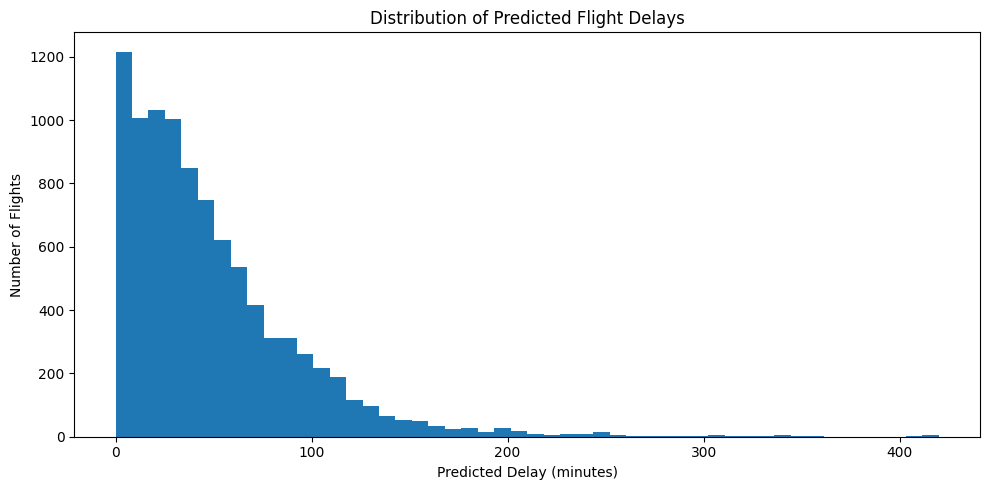

In [22]:
plt.figure(figsize=(10, 5))

plt.hist(
    prediction_output["target"],
    bins=50
)

plt.xlabel("Predicted Delay (minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Predicted Flight Delays")

plt.tight_layout()
plt.show()


## 20. Inspect the Largest Predicted Delays

Extreme predictions deserve extra inspection because rare, very long delays were the most difficult cases for the training models.


In [23]:
prediction_output.sort_values(
    "target",
    ascending=False
).head(20)


,ID,DATOP,FLTID,DEPSTN,ARRSTN,target
8221,test_id_8398,2018-09-28,TU 0216,TUN,IST,420.003205
6953,test_id_7256,2018-09-07,TU 0216,TUN,IST,419.984068
7039,test_id_7333,2018-09-14,TU 0216,TUN,IST,419.672102
5206,test_id_5684,2018-09-10,TU 0216,TUN,IST,414.450868
7832,test_id_8047,2018-09-24,TU 0216,TUN,IST,413.118915
5252,test_id_5725,2018-09-11,TU 0216,TUN,IST,407.830119
6859,test_id_7171,2018-09-13,TU 0250,MIR,NCE,358.043187
5297,test_id_5766,2018-09-04,TU 0928,TUN,MRS,345.877980
6764,test_id_7086,2018-09-08,TU 0902,TUN,MRS,343.229169
6574,test_id_6915,2018-09-03,TU 3060,TUN,CDG,340.617302


## 21. Create the Submission File

The final prediction file contains only the identifier and predicted target.


In [24]:
submission = prediction_output[
    ["ID", "target"]
].copy()

submission.to_csv(
    "flight_delay_predictions.csv",
    index=False
)

submission.head()


,ID,target
0,test_id_0,1.473469
1,test_id_1,49.322835
2,test_id_10,25.998267
3,test_id_100,16.947265
4,test_id_1000,185.882690


## 22. Final Validation

Before using the file, confirm that:

- every test observation has one prediction
- there are no missing targets
- IDs remain unique
- delay predictions are non-negative


In [25]:
print(
    "Number of test rows:",
    len(test_df)
)

print(
    "Number of predictions:",
    len(submission)
)

print(
    "Missing predictions:",
    submission["target"].isna().sum()
)

print(
    "Duplicated IDs:",
    submission["ID"].duplicated().sum()
)

print(
    "Minimum prediction:",
    submission["target"].min()
)

print(
    "Maximum prediction:",
    submission["target"].max()
)


Number of test rows: 9333
Number of predictions: 9333
Missing predictions: 0
Duplicated IDs: 0
Minimum prediction: 0.0
Maximum prediction: 420.0032054659438


## Conclusion

The test data has now passed through the same core cleaning and feature-engineering workflow as the training data before being sent to the fitted model.

This is essential for reliable machine-learning inference: **the model must see predictors with the same meaning, format, and construction at training and prediction time**.

The final file `flight_delay_predictions.csv` contains the predicted flight delay in minutes for each test flight.
